<a href="https://colab.research.google.com/github/Charmpy/RTC_cup/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22YOLO_TU2U_ready_(1)_(1)_(1)_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#INFRARED UAV DETECTION ON THERMALUAV2UAV DATASET
##EXPERIMENTS WITH YOLOv5 AND YOLOv8
###AUTHOR: VOLTAN GABRIELE
####AFFILIATION: University of Udine - Department of Mathematics, Computer Science and Physics

In [ ]:
# Если ещё не установлено
!pip install albumentations==1.4.4

import os
import random
import cv2
import albumentations as A
from google.colab.patches import cv2_imshow   # если не в Colab — закомментировать
import math

# --- Параметры: меняй их ---
IMG_DIR = "/content/ThermalUAV2UAV_Dataset/train/images"   # исходные PNG
LBL_DIR = "/content/ThermalUAV2UAV_Dataset/train/labels"   # исходные .txt (YOLO)
AUG_IMG_DIR = "/content/AUG/images"    # куда сохранять новые PNG
AUG_LBL_DIR = "/content/AUG/labels"    # куда сохранять новые TXT

NUM_SOURCE_IMAGES = 50    # сколько изображений взять из папки (0 — все)
N_AUG_PER_IMAGE = 3        # сколько аугментаций на одно изображение

# --- Создаём папки ---
os.makedirs(AUG_IMG_DIR, exist_ok=True)
os.makedirs(AUG_LBL_DIR, exist_ok=True)

# --- Albumentations pipeline с ReplayCompose для логов ---
def build_transform():
    # ReplayCompose возвращает 'replay' в результатах с информацией о применённых трансформациях
    return A.ReplayCompose([
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(p=0.4),
        A.GaussianBlur(blur_limit=5, p=0.3),
        A.Rotate(limit=10, p=0.5),
        A.RandomGamma(p=0.3),
    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels']))

transform = build_transform()

# --- Утилиты ---
def read_yolo_labels(path):
    """
    Читает .txt в формате YOLO: class x_center y_center width height (нормированные)
    Возвращает два списка: bboxes и labels
    """
    bboxes = []
    labels = []
    if not os.path.exists(path):
        return bboxes, labels
    with open(path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls = int(parts[0])
            x = float(parts[1]); y = float(parts[2]); w = float(parts[3]); h = float(parts[4])
            # защита от NaN/inf
            if any(math.isnan(v) or math.isinf(v) for v in (x,y,w,h)):
                continue
            # корректируем (клипер) — если небольшие погрешности выходят за [0,1]
            eps = 1e-9
            x = min(max(x, 0.0 + eps), 1.0 - eps)
            y = min(max(y, 0.0 + eps), 1.0 - eps)
            w = min(max(w, 0.0 + eps), 1.0 - eps)
            h = min(max(h, 0.0 + eps), 1.0 - eps)
            bboxes.append([x, y, w, h])
            labels.append(cls)
    return bboxes, labels

def save_yolo_labels(path, labels, bboxes):
    with open(path, 'w') as f:
        for cls, (x,y,w,h) in zip(labels, bboxes):
            f.write(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

# --- Основной цикл ---
all_files = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith(".png")])
total_available = len(all_files)
if total_available == 0:
    raise RuntimeError(f"В папке {IMG_DIR} нет PNG изображений. Проверь путь.")

# определяем, какие файлы взять
if NUM_SOURCE_IMAGES <= 0 or NUM_SOURCE_IMAGES >= total_available:
    chosen_files = all_files
else:
    chosen_files = random.sample(all_files, NUM_SOURCE_IMAGES)

print(f"Всего доступно: {total_available} PNG. Будем использовать: {len(chosen_files)} файлов.")
created = 0
errors = 0

for idx, img_name in enumerate(chosen_files, start=1):
    img_path = os.path.join(IMG_DIR, img_name)
    label_path = os.path.join(LBL_DIR, img_name.replace(".png", ".txt"))

    img = cv2.imread(img_path)
    if img is None:
        print(f"[{idx}] ❌ Не удалось прочитать {img_name}, пропускаю.")
        errors += 1
        continue

    bboxes, labels = read_yolo_labels(label_path)
    if len(bboxes) == 0:
        # если нет разметки — можно пропустить или генерировать без bbox
        print(f"[{idx}] ⚠️ Для {img_name} нет разметки, пропускаю.")
        continue

    for k in range(N_AUG_PER_IMAGE):
        try:
            # Пропуск пустых bbox будет обработан в albumentations (он может вернуть пустой список)
            result = transform(image=img, bboxes=bboxes, class_labels=labels)
        except Exception as e:
            # отлавливаем ошибки (в том числе ValueError с bbox)
            print(f"[{idx}] Ошибка при аугментации {img_name} (итерация {k}): {e}")
            errors += 1
            continue

        aug_img = result['image']
        aug_bboxes = result.get('bboxes', [])
        aug_labels = result.get('class_labels', [])

        # Если все bbox "выпали" (например, после сильного кропа) — пропускаем сохранение
        if len(aug_bboxes) == 0:
            print(f"[{idx}] {img_name} -> aug{k}: bbox пустой после аугментации, пропускаю.")
            continue

        base = img_name.replace('.png', '')
        new_img_name = f"{base}_aug{k}.png"
        new_lbl_name = f"{base}_aug{k}.txt"

        new_img_path = os.path.join(AUG_IMG_DIR, new_img_name)
        new_lbl_path = os.path.join(AUG_LBL_DIR, new_lbl_name)

        # сохраняем
        cv2.imwrite(new_img_path, aug_img)
        save_yolo_labels(new_lbl_path, aug_labels, aug_bboxes)
        created += 1

        # --- выводим лог: какие трансформации с какими параметрами ---
        replay = result.get('replay', {})
        applied = replay.get('transforms', [])
        # replay содержит список dict-ов: каждый с ключами 'name' и 'params' и 'applied'
        # Но в некоторых версиях replay — словарь с ключами 'replay'->list; обрабатываем гибко:
        # Albumentations обычно хранит список в replay['transforms'] — проверим:
        if isinstance(replay, dict) and 'transforms' in replay:
            tlist = replay['transforms']
        else:
            tlist = []

        # Форматируем строку с перечислением применённых трансформаций и их параметров
        applied_strs = []
        for t in tlist:
            # т может быть dict с полями 'name','applied','params'
            name = t.get('name', str(t))
            applied_flag = t.get('applied', False)
            if not applied_flag:
                continue
            params = t.get('params', {})
            # читаем только значимые параметры, сериализуем кратко
            params_str = ", ".join(f"{k}={v}" for k,v in params.items() if v is not None)
            applied_strs.append(f"{name}({params_str})")

        # Если replay пустой или не в ожидаемом формате — просто напечатаем, что что-то применилось
        if applied_strs:
            print(f"[{idx}] {img_name} -> {new_img_name} : применено -> " + "; ".join(applied_strs))
        else:
            # fallback: перечислим вероятностные операции (вручную)
            print(f"[{idx}] {img_name} -> {new_img_name} : аугментация выполнена (параметры недоступны в replay)")

# Финальный отчёт
print(f"\nГотово. Создано: {created} изображений. Ошибок/пропусков: {errors}.")
print("Сохранено в папках:")
print("  Изображения:", AUG_IMG_DIR)
print("  Разметки   :", AUG_LBL_DIR)

# показать один пример, если есть
if created > 0:
    sample = random.choice(sorted(os.listdir(AUG_IMG_DIR)))
    print("Пример аугментированного файла:", sample)
    try:
        cv2_imshow(cv2.imread(os.path.join(AUG_IMG_DIR, sample)))
    except Exception as e:
        print("Не удалось показать изображение (не Colab?):", e)


ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 324, in run
    session = self.get_default_session(options)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/index_command.py", line 71, in get_default_session
    self._session = self.enter_context(self._build_session(options))
                                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/index_command.py", line 100, in _build_session
    session = 

KeyboardInterrupt: 

In [ ]:
!zip -r /content/AUG.zip /content/AUG/

  adding: content/AUG/ (stored 0%)
  adding: content/AUG/labels/ (stored 0%)
  adding: content/AUG/labels/01239_aug2.txt (deflated 8%)
  adding: content/AUG/labels/01410_aug0.txt (deflated 28%)
  adding: content/AUG/labels/01425_aug2.txt (deflated 8%)
  adding: content/AUG/labels/01095_aug0.txt (deflated 8%)
  adding: content/AUG/labels/01434_aug2.txt (deflated 5%)
  adding: content/AUG/labels/01438_aug1.txt (deflated 8%)
  adding: content/AUG/labels/c40_aug1.txt (deflated 8%)
  adding: content/AUG/labels/01286_aug2.txt (deflated 8%)
  adding: content/AUG/labels/01267_aug1.txt (deflated 13%)
  adding: content/AUG/labels/01340_aug1.txt (deflated 8%)
  adding: content/AUG/labels/01245_aug2.txt (stored 0%)
  adding: content/AUG/labels/02560_aug0.txt (deflated 8%)
  adding: content/AUG/labels/01378_aug2.txt (deflated 13%)
  adding: content/AUG/labels/01345_aug0.txt (deflated 13%)
  adding: content/AUG/labels/01308_aug0.txt (deflated 5%)
  adding: content/AUG/labels/01435_aug2.txt (deflated

In [ ]:
!pip install torch torchvision torchaudio
import torch
print("Torch version:", torch.__version__)

!rm -rf yolov5
!git clone https://github.com/ultralytics/yolov5.git
%cd yolov5

!pip install -r requirements.txt

!sed -i "s/ckpt = torch.load(weights, map_location='cpu')/import torch.serialization; torch.serialization.add_safe_globals([dict]); ckpt = torch.load(weights, map_location='cpu', weights_only=False)/" train.py

!grep "weights_only" -n train.py



Torch version: 2.9.0+cu126
Cloning into 'yolov5'...
remote: Enumerating objects: 17757, done.
remote: Counting objects: 100% (122/122), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 17757 (delta 73), reused 39 (delta 39), pack-reused 17635 (from 3)
Receiving objects: 100% (17757/17757), 17.15 MiB | 18.24 MiB/s, done.
Resolving deltas: 100% (12055/12055), done.
/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 72.4 MB/s eta 0:00:00


In [ ]:
!sed -i "1i import torch.serialization; import numpy; torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct, dict])" /content/yolov5/models/experimental.py

In [ ]:
# Патч для experimental.py
!sed -i "1i import torch.serialization; import numpy; torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct, numpy.ndarray, dict])" /content/yolov5/models/experimental.py

#Importing the ThermalUAV2UAV dataset

In [ ]:
%cd /content
!git clone https://github.com/GabryV00/ThermalUAV2UAV_Dataset.git

/content
Cloning into 'ThermalUAV2UAV_Dataset'...
remote: Enumerating objects: 7128, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 7128 (delta 7), reused 0 (delta 0), pack-reused 7113 (from 1)
Receiving objects: 100% (7128/7128), 989.70 MiB | 16.47 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Updating files: 100% (7716/7716), done.


##Removal of empty labels

#Creating the .yaml file for YOLO

In [ ]:
import yaml
dict_ = {"names" : ["UAV"],"nc" : 1, "train" : "/content/ThermalUAV2UAV_Dataset/train/images", "val" : "/content/ThermalUAV2UAV_Dataset/val/images", "test": "/content/ThermalUAV2UAV_Dataset/test/images"}
with open(r'/content/ThermalUAV2UAV_Dataset/dataset.yaml', 'w') as file:
    documents = yaml.dump(dict_, file)


In [ ]:
!unzip -q /content/Bird-IR-train.zip -d /content/Bird-IR-train-2

unzip:  cannot find or open /content/Bird-IR-train.zip, /content/Bird-IR-train.zip.zip or /content/Bird-IR-train.zip.ZIP.


In [ ]:
dict_ = {"names" : ["UAV"],"nc" : 1, "train" : "/content/Bird-IR-train/train/images", "val" : "/content/Bird-IR-train/valid/images", "test": "/content/Bird-IR-train/valid/images"}
with open(r'/content/Bird-IR-train/dataset.yaml', 'w') as file:
    documents = yaml.dump(dict_, file)

In [ ]:
!unzip -q /content/IR_Drone_New_aug.zip -d /content/

In [ ]:
dict_ = {"names" : ["UAV"],"nc" : 1, "train" : "/content/IR_Drone_New_aug/train/images", "val" : "/content/IR_Drone_New_aug/val/images", "test": "/content/IR_Drone_New_aug/val/images"}
with open(r'/content/IR_Drone_New_aug/dataset.yaml', 'w') as file:
    documents = yaml.dump(dict_, file)

#YOLOv5


##20 EPOCHS - SMALL YOLO

In [ ]:
%cd /content/yolov5
!python train.py --img 640 --rect --batch 16 --epochs 20 --data /content/ThermalUAV2UAV_Dataset/dataset.yaml --cfg models/yolov5s.yaml --weights yolov5s.pt --cache --name ep20small --exist-ok

/content/yolov5

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/content/yolov5/train.py", line 39, in <module>
    import val  # for end-of-epoch mAP
  File "/content/yolov5/val.py", line 37, in <module>
    from models.common import DetectMultiBackend
  File "/content/yolov5/models/common.py", line 24, in <module>
    from utils.dataloaders import exif_transpose, letterbox
  File "/content/yolov5/utils/dataloaders.py", line 29, in <module>
    from utils.augmentations import Albumentations, augment_hsv, copy_paste, letterbox, mixup, random_perspective
  File "

In [ ]:
!ls /content/yolov5/runs/train
!ls /content/yolov5/runs/train/ep20small2/weights
!rm -rf /content/yolov5/runs/val/*

ep20small
ls: cannot access '/content/yolov5/runs/train/ep20small2/weights': No such file or directory


In [ ]:
!python val.py --img 640 --batch 16 --data /content/ThermalUAV2UAV_Dataset/dataset.yaml --weights /content/yolov5/runs/train/ep20small/weights/best.pt --name ep20small --exist-ok

val: data=/content/ThermalUAV2UAV_Dataset/dataset.yaml, weights=['/content/yolov5/runs/train/ep20small4/weights/best.pt'], batch_size=16, imgsz=640, conf_thres=0.001, iou_thres=0.6, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=ep20small, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v6.1-306-gfbe67e46 Python-3.11.12 torch-2.0.1+cu117 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
YOLOv5s summary: 213 layers, 7012822 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning '/content/ThermalUAV2UAV_Dataset/val/labels.cache' images and labels... 646 found, 220 missing, 0 empty, 0 corrupt: 100% 866/866 [00:00<?, ?it/s]
               Class     Images     Labels          P          R     mAP@.5 mAP@.5:.95:   2% 1/55 [00:00<00:37,  1.46it/s]Exception in thread Thread-3 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.11/threading.py", line 1045, in

###METRICS ON TEST SET

In [ ]:
!python val.py --img 640 --batch 16 --data /content/ThermalUAV2UAV_Dataset/dataset.yaml --weights /content/yolov5/runs/train/ep20small/weights/best.pt --name TESTep20small --task test

val: data=/content/ThermalUAV2UAV_Dataset/dataset.yaml, weights=['/content/yolov5/runs/train/ep20small4/weights/best.pt'], batch_size=16, imgsz=640, conf_thres=0.001, iou_thres=0.6, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=TESTep20small, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v6.1-306-gfbe67e46 Python-3.11.12 torch-2.0.1+cu117 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
YOLOv5s summary: 213 layers, 7012822 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning '/content/ThermalUAV2UAV_Dataset/test/labels' images and labels...324 found, 152 missing, 0 empty, 0 corrupt: 100% 476/476 [00:01<00:00, 431.71it/s]
test: New cache created: /content/ThermalUAV2UAV_Dataset/test/labels.cache
               Class     Images     Labels          P          R     mAP@.5 mAP@.5:.95:   3% 1/30 [00:00<00:18,  1.54it/s]Exception in thread Thread-6 (plot_images):
Traceba

##30 EPOCHS - SMALL YOLO

In [ ]:
%cd /content/yolov5
!python train.py --img 640 --rect --batch 16 --epochs 30 --data /content/ThermalUAV2UAV_Dataset/dataset.yaml --cfg models/yolov5s.yaml --weights yolov5s.pt --cache --name ep30small --exist-ok --save-period 1

Выходные данные были обрезаны до нескольких последних строк (5000).
  with torch.cuda.amp.autocast(amp):
      14/29      3.55G    0.03308   0.005435          0         19        640:  46% 73/158 [00:15<00:16,  5.05it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      14/29      3.55G    0.03309   0.005476          0         20        640:  47% 74/158 [00:15<00:15,  5.27it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      14/29      3.55G    0.03299   0.005567          0         31        640:  47% 75/158 [00:15<00:15,  5.33it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda

In [ ]:
!zip -r /content/weight.zip /content/yolov5/runs/train/ep30small/

  adding: content/yolov5/runs/train/ep30small/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small/val_batch1_labels.jpg (deflated 7%)
  adding: content/yolov5/runs/train/ep30small/F1_curve.png (deflated 16%)
  adding: content/yolov5/runs/train/ep30small/train_batch2.jpg (deflated 4%)
  adding: content/yolov5/runs/train/ep30small/val_batch2_labels.jpg (deflated 15%)
  adding: content/yolov5/runs/train/ep30small/R_curve.png (deflated 16%)
  adding: content/yolov5/runs/train/ep30small/val_batch1_pred.jpg (deflated 6%)
  adding: content/yolov5/runs/train/ep30small/confusion_matrix.png (deflated 39%)
  adding: content/yolov5/runs/train/ep30small/train_batch1.jpg (deflated 13%)
  adding: content/yolov5/runs/train/ep30small/labels.jpg (deflated 30%)
  adding: content/yolov5/runs/train/ep30small/val_batch2_pred.jpg (deflated 14%)
  adding: content/yolov5/runs/train/ep30small/val_batch0_labels.jpg (deflated 8%)
  adding: content/yolov5/runs/train/ep30small/events.out.tfevents.1764857308.

In [ ]:
!unzip -q /content/ep30small.zip -d /content/yolov5/runs/train/

###METRICS ON TEST SET

In [ ]:
%cd /content/yolov5
!rm -rf runs/detect/TESTep30small
!python3 detect.py --source '/content/ThermalUAV2UAV_Dataset/test/images' --weights '/content/yolov5/runs/train/ep30small/weights/best.pt' --conf 0.001 --iou 0.5 --save-txt --save-conf --augment --name 'TESTep30small' --exist-ok

/content/yolov5
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
detect: weights=['/content/yolov5/runs/train/ep30small/weights/best.pt'], source=/content/ThermalUAV2UAV_Dataset/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.001, iou_thres=0.5, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=True, visualize=False, update=False, project=runs/detect, name=TESTep30small, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-450-g781b9d57 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
YOLOv5s

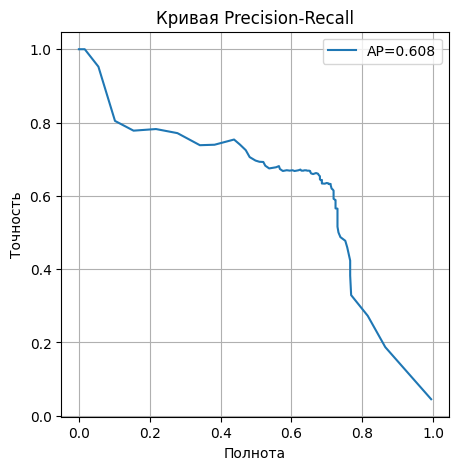

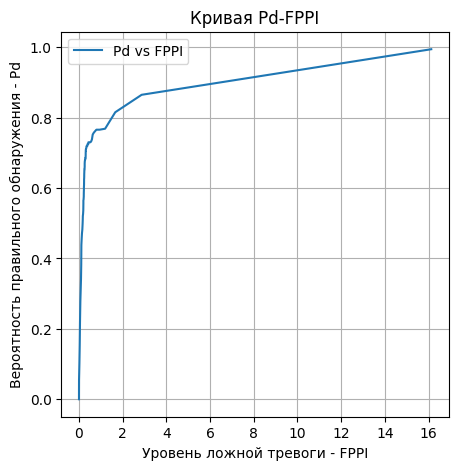

=== Итоговые метрики при пороге confidence = 0.500 ===
Всего изображений N = 476
TP (boxes)   = 247
FP (boxes)   = 130
FN (boxes)   = 116
Всего предсказаний                = 8035
Предсказаний учтено при пороге   = 377
Precision    = 0.6552
Recall (Pd)  = 0.6804
FPPI         = 130 / 476 = 0.273109

=== Метрики при целевом FPPI = 0.1 ===
Найденный порог confidence     = 0.879
Recall (Pd) при этом пороге   = 0.3416


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc


# ----------------- Конфигурация -----------------
LABEL_DIR    = "/content/ThermalUAV2UAV_Dataset/test/labels"
PRED_DIR     = "runs/detect/TESTep30small/labels"
IMAGE_DIR = "/content/ThermalUAV2UAV_Dataset/test/images"

CONF_THRESH  = 0.001
IOU_THRESH   = 0.5
TH_METRIC    = 0.5

# ----------------- Функции -----------------
def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w/2) * img_w
    y1 = (yc - h/2) * img_h
    x2 = (xc + w/2) * img_w
    y2 = (yc + h/2) * img_h
    return np.array([x1, y1, x2, y2], dtype=float)

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2-ix1)*(iy2-iy1)
    area1 = (box1[2]-box1[0])*(box1[3]-box1[1])
    area2 = (box2[2]-box2[0])*(box2[3]-box2[1])
    return inter / (area1 + area2 - inter)

# ----------------- Сбор GT и предсказаний -----------------
all_labels  = []
all_scores  = []
per_image_gt   = {}
per_image_pred = {}

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

for img_file in image_files:
    base = os.path.splitext(img_file)[0]
    gt_path = os.path.join(LABEL_DIR, base + ".txt")
    pred_path = os.path.join(PRED_DIR, base + ".txt")

    gt_boxes = []
    if os.path.exists(gt_path) and os.stat(gt_path).st_size > 0:
        gt_boxes = [yolo_to_corners(list(map(float, line.strip().split()[1:5])))
                    for line in open(gt_path) if len(line.strip().split()) >= 5]
    per_image_gt[base] = len(gt_boxes)

    pred_boxes, pred_scores = [], []
    if os.path.exists(pred_path):
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) >= 6:
                score = float(parts[5])
                if score >= CONF_THRESH:
                    pred_scores.append(score)
                    pred_boxes.append(yolo_to_corners(list(map(float, parts[1:5]))))

    used_gt = set()
    per_image_pred[base] = []
    for pbox, pscore in zip(pred_boxes, pred_scores):
        best_iou, best_j = 0.0, -1
        for j, gbox in enumerate(gt_boxes):
            if j in used_gt:
                continue
            cur_iou = iou(pbox, gbox)
            if cur_iou > best_iou:
                best_iou, best_j = cur_iou, j
        is_tp = best_iou >= IOU_THRESH
        if is_tp:
            used_gt.add(best_j)
        all_scores.append(pscore)
        all_labels.append(1 if is_tp else 0)
        per_image_pred[base].append((pscore, is_tp))

    n_fn = len(gt_boxes) - len(used_gt)
    all_scores.extend([0.0] * n_fn)
    all_labels.extend([1] * n_fn)

# ----------------- Построение ROC -----------------
fpr, tpr, _ = roc_curve(all_labels, all_scores)
roc_auc = auc(fpr, tpr)

# ----------------- Ручной PR + AP + Pd-FPPI -----------------
unique_thresholds = np.linspace(0.0, 1.0, 100)
pr_list, re_list = [], []
fp_list, pd_list = [], []

for thresh in unique_thresholds:
    TP = FP = FN = 0
    for fname, ngt in per_image_gt.items():
        preds = per_image_pred.get(fname, [])
        sel = [(s, is_tp) for (s, is_tp) in preds if s >= thresh]
        tp_i = sum(is_tp for _, is_tp in sel)
        fp_i = len(sel) - tp_i
        fn_i = ngt - tp_i
        TP += tp_i
        FP += fp_i
        FN += max(fn_i, 0)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 1.0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    fppi      = FP / N_images

    pr_list.append(precision)
    re_list.append(recall)
    pd_list.append(recall)
    fp_list.append(fppi)

# ----------------- AP (Area under PR curve) -----------------
re_arr = np.array(re_list)
pr_arr = np.array(pr_list)
sorted_idx = np.argsort(re_arr)
re_sorted = re_arr[sorted_idx]
pr_sorted = pr_arr[sorted_idx]
AP = np.trapezoid(pr_sorted, re_sorted)

# ----------------- Визуализация -----------------
re_list_1 = re_list
pr_list_1 = pr_list
AP_1 = AP
plt.figure(figsize=(5,5))
plt.plot(re_list_1, pr_list_1, label=f"AP={AP_1:.3f}")
plt.xlabel("Полнота")
plt.ylabel("Точность")
plt.grid()
plt.legend()
plt.title("Кривая Precision-Recall")
plt.show()

fp_list_1 = fp_list
pd_list_1 = pd_list

plt.figure(figsize=(5,5))
plt.plot(fp_list, pd_list, label="Pd vs FPPI")
plt.xlabel("Уровень ложной тревоги - FPPI")
plt.ylabel("Вероятность правильного обнаружения - Pd")
plt.grid()
plt.legend()
plt.title("Кривая Pd-FPPI")
plt.show()

# ----------------- Финальный подсчёт при TH_METRIC -----------------
TP = FP = FN = 0
n_total_preds = 0
n_counted_preds = 0
for fname, ngt in per_image_gt.items():
    preds = per_image_pred.get(fname, [])
    n_total_preds += len(preds)
    sel = [(s, is_tp) for (s, is_tp) in preds if s >= TH_METRIC]
    n_counted_preds += len(sel)
    tp_i = sum(is_tp for _, is_tp in sel)
    fp_i = len(sel) - tp_i
    fn_i = ngt - tp_i

    TP += tp_i
    FP += fp_i
    FN += max(fn_i, 0)

Prec = TP / (TP + FP) if TP + FP > 0 else 0
Rec  = TP / (TP + FN) if TP + FN > 0 else 0
FPPI = FP / N_images

print("=== Итоговые метрики при пороге confidence = {:.3f} ===".format(TH_METRIC))
print(f"Всего изображений N = {N_images}")
print(f"TP (boxes)   = {TP}")
print(f"FP (boxes)   = {FP}")
print(f"FN (boxes)   = {FN}")
print(f"Всего предсказаний                = {n_total_preds}")
print(f"Предсказаний учтено при пороге   = {n_counted_preds}")
print(f"Precision    = {Prec:.4f}")
print(f"Recall (Pd)  = {Rec:.4f}")
print(f"FPPI         = {FP} / {N_images} = {FPPI:.6f}")

# ----------------- Поиск метрики при заданном FPPI -----------------
TARGET_FPPI = 0.1

conf_at_fppi = None
pd_at_fppi = None
for fppi_val, pd_val, conf_thresh in zip(fp_list, pd_list, unique_thresholds):
    if fppi_val <= TARGET_FPPI:
        conf_at_fppi = conf_thresh
        pd_at_fppi = pd_val
        break

if conf_at_fppi is not None:
    print(f"\n=== Метрики при целевом FPPI = {TARGET_FPPI} ===")
    print(f"Найденный порог confidence     = {conf_at_fppi:.3f}")
    print(f"Recall (Pd) при этом пороге   = {pd_at_fppi:.4f}")
else:
    print(f"\nFPPI = {TARGET_FPPI} не достигнут ни при одном пороге.")

In [ ]:
!zip -r /content/runs_results_small.zip /content/yolov5/runs

  adding: content/yolov5/runs/ (stored 0%)
  adding: content/yolov5/runs/train/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small/val_batch2_labels.jpg (deflated 12%)
  adding: content/yolov5/runs/train/ep30small/train_batch2.jpg (deflated 7%)
  adding: content/yolov5/runs/train/ep30small/R_curve.png (deflated 17%)
  adding: content/yolov5/runs/train/ep30small/confusion_matrix.png (deflated 39%)
  adding: content/yolov5/runs/train/ep30small/labels.jpg (deflated 30%)
  adding: content/yolov5/runs/train/ep30small/labels_correlogram.jpg (deflated 36%)
  adding: content/yolov5/runs/train/ep30small/results.csv (deflated 84%)
  adding: content/yolov5/runs/train/ep30small/results.png (deflated 9%)
  adding: content/yolov5/runs/train/ep30small/val_batch2_pred.jpg (deflated 11%)
  adding: content/yolov5/runs/train/ep30small/opt.yaml (deflated 49%)
  adding: content/yolov5/runs/train/ep30small/events.out.tfevents.1764857308.7de90

In [ ]:
!zip -r /content/ThermalUAV2UAV_Dataset.zip /content/ThermalUAV2UAV_Dataset

Выходные данные были обрезаны до нескольких последних строк (5000).
  adding: content/ThermalUAV2UAV_Dataset/train/images/527.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/c776.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/649.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/127.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/01744.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/559.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/c433.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/02017.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/367.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/01130.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/c761.png (deflated 0%)
  adding: content/ThermalUAV2UAV_Dataset/train/images/01649.png (deflated 0%)
  adding:

##DETECTING ON TEST SET with different conf's values

##ZIP RESULTS TO SAVE THEM

# Птички

In [ ]:
!rm -rf runs/detect/TESTep30small_bird
!python3 detect.py --source '/content/Bird-IR-train/Bird-IR-train/valid/images' --weights '/content/yolov5/runs/train/ep30small/weights/best.pt' --save-txt --save-conf --conf 0.001 --iou 0.5 --augment --name 'TESTep30small_bird' --exist-ok

detect: weights=['/content/yolov5/runs/train/ep30small/weights/best.pt'], source=/content/Bird-IR-train/Bird-IR-train/valid/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.001, iou_thres=0.5, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=True, visualize=False, update=False, project=runs/detect, name=TESTep30small_bird, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-450-g781b9d57 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
YOLOv5s summary: 157 layers, 7012822 parameters, 0 gradients, 15.8 GFLOPs
image 1/200 /content/Bird-IR-train/Bird-IR-train/valid/images/scene02167_jpg.rf.1f12414941b2feab1cf40427f42dbc51.jpg: 640x640 7 UAVs, 82.0ms
image 2/200 /content/Bird-IR-train/Bird-IR-train/valid/images/scene02168_jpg.rf.0175a99c854131ac7cecb25334db

In [ ]:
import os
import numpy as np

# ----------------- Конфигурация -----------------
pred_dir       = "runs/detect/TESTep30small_bird/labels"
image_dir      = "/content/Bird-IR-train/Bird-IR-train/valid/images"
gt_dir         = "/content/Bird-IR-train/Bird-IR-train/valid/labels"
conf_threshold = 0
iou_threshold  = 0.5
# ------------------------------------------------

def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return np.array([x1, y1, x2, y2])

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2 - ix1) * (iy2 - iy1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area1 + area2 - inter)

# Список изображений
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

# Карты предсказаний и GT
pred_map = {
    os.path.splitext(f)[0]: os.path.join(pred_dir, f)
    for f in os.listdir(pred_dir)
    if f.endswith(".txt")
}
gt_map = {
    os.path.splitext(f)[0]: os.path.join(gt_dir, f)
    for f in os.listdir(gt_dir)
    if f.endswith(".txt")
}

images_without_preds = 0
images_completely_empty = 0
total_fp = 0
fp_on_birds = 0
total_gt_birds = 0

for img in image_files:
    base = os.path.splitext(img)[0]
    pred_path = pred_map.get(base, None)
    gt_path   = gt_map.get(base, None)

    # Загружаем GT боксы птиц
    gt_boxes = []
    if gt_path and os.stat(gt_path).st_size > 0:
        for line in open(gt_path):
            parts = line.strip().split()
            if len(parts) >= 5:
                gt_box = yolo_to_corners(list(map(float, parts[1:5])))
                gt_boxes.append(gt_box)
    total_gt_birds += len(gt_boxes)

    # Считаем предсказания
    preds = []
    if pred_path and os.stat(pred_path).st_size > 0:
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) < 6:
                continue
            conf = float(parts[5])
            if conf >= conf_threshold:
                box = yolo_to_corners(list(map(float, parts[1:5])))
                preds.append(box)

    if len(preds) == 0:
        images_without_preds += 1
        if pred_path is None or os.stat(pred_path).st_size == 0:
            images_completely_empty += 1
        continue

    total_fp += len(preds)

    # Проверяем пересечения предсказаний с GT боксами
    for pbox in preds:
        matched = False
        for gbox in gt_boxes:
            if iou(pbox, gbox) >= iou_threshold:
                matched = True
                break
        if matched:
            fp_on_birds += 1

# Метрики
fppi_total = total_fp / N_images
fppi_birds = fp_on_birds / N_images

# Вывод
print(f"Всего изображений:                         {N_images}")
print(f"Число птиц на этих изображениях:           {total_gt_birds}")
print(f"Порог confidence:                          {conf_threshold:.2f}")
print(f"Общее число предсказаний (FP):             {total_fp}")
print(f"FPPI (все срабатывания):                   {fppi_total:.6f}")
print(f"FP на птицах (восприняты как дрон):        {fp_on_birds}")
print(f"FPPI на птицах:                            {fppi_birds:.6f}")
print(f"Изображений без предсказаний:              {images_without_preds}")
print(f"Из них полностью пустых файлов (нет .txt): {images_completely_empty}")


Всего изображений:                         200
Число птиц на этих изображениях:           229
Порог confidence:                          0.00
Общее число предсказаний (FP):             7776
FPPI (все срабатывания):                   38.880000
FP на птицах (восприняты как дрон):        87
FPPI на птицах:                            0.435000
Изображений без предсказаний:              0
Из них полностью пустых файлов (нет .txt): 0


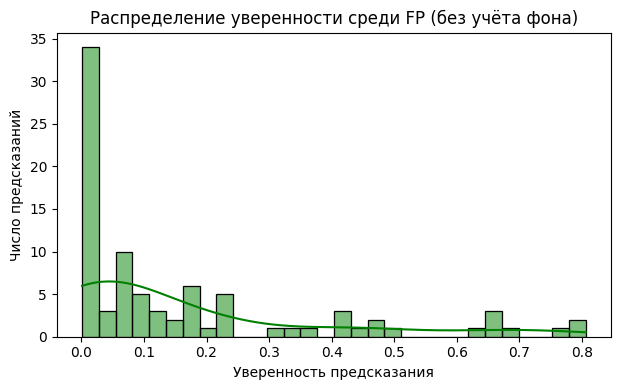

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------- Конфигурация -----------------
pred_dir       = "runs/detect/TESTep30small_bird/labels"
image_dir      = "/content/Bird-IR-train/Bird-IR-train/valid/images"
gt_dir         = "/content/Bird-IR-train/Bird-IR-train/valid/labels"
conf_threshold = 0.5
iou_threshold  = 0.5
class_id_drone = 0
# ------------------------------------------------

def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return np.array([x1, y1, x2, y2])

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2 - ix1) * (iy2 - iy1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area1 + area2 - inter)

# Список изображений
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

# Карты предсказаний и GT
pred_map = {
    os.path.splitext(f)[0]: os.path.join(pred_dir, f)
    for f in os.listdir(pred_dir)
    if f.endswith(".txt")
}
gt_map = {
    os.path.splitext(f)[0]: os.path.join(gt_dir, f)
    for f in os.listdir(gt_dir)
    if f.endswith(".txt")
}

images_without_preds = 0
images_completely_empty = 0
total_fp = 0
fp_on_birds = 0
total_gt_birds = 0

all_fp_confidences = []
bird_fp_confidences = []

for img in image_files:
    base = os.path.splitext(img)[0]
    pred_path = pred_map.get(base, None)
    gt_path   = gt_map.get(base, None)

    # Загружаем GT боксы птиц
    gt_boxes = []
    if gt_path and os.stat(gt_path).st_size > 0:
        for line in open(gt_path):
            parts = line.strip().split()
            if len(parts) >= 5:
                gt_box = yolo_to_corners(list(map(float, parts[1:5])))
                gt_boxes.append(gt_box)
    total_gt_birds += len(gt_boxes)

    # Считаем предсказания
    preds = []
    pred_confs = []
    if pred_path and os.stat(pred_path).st_size > 0:
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) < 6:
                continue
            cid = int(parts[0])
            conf = float(parts[5])
            if cid == class_id_drone:
                box = yolo_to_corners(list(map(float, parts[1:5])))
                preds.append(box)
                pred_confs.append(conf)

    if len(preds) == 0:
        images_without_preds += 1
        if pred_path is None or os.stat(pred_path).st_size == 0:
            images_completely_empty += 1
        continue

    total_fp += len(preds)
    all_fp_confidences.extend(pred_confs)

    # Проверяем пересечения предсказаний с GT боксами
    for pbox, conf in zip(preds, pred_confs):
        matched = False
        for gbox in gt_boxes:
            if iou(pbox, gbox) >= iou_threshold:
                matched = True
                break
        if matched:
            fp_on_birds += 1
            bird_fp_confidences.append(conf)

# Метрики
fppi_total = total_fp / N_images
fppi_birds = fp_on_birds / N_images

# Построение гистограмм
plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 2)
sns.histplot(bird_fp_confidences, bins=30, kde=True, color='green')
plt.xlabel("Уверенность предсказания")
plt.ylabel("Число предсказаний")
plt.title("Распределение уверенности среди FP (без учёта фона)")

plt.tight_layout()
plt.show()


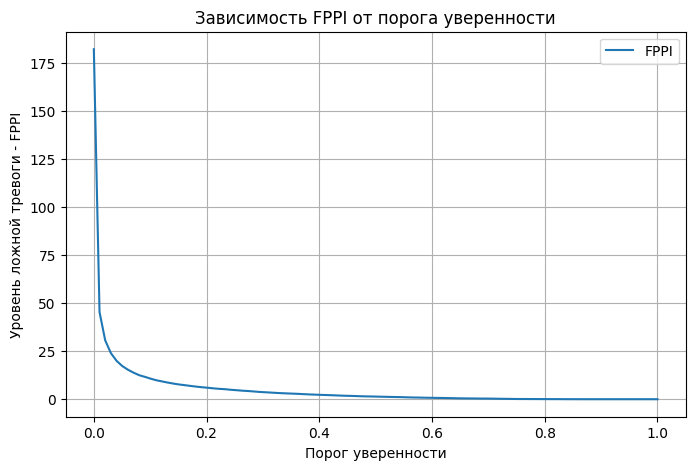


=== Confidence при FPPI <= 0.01 ===
Confidence threshold = 0.8586
FPPI = 0.010000


In [ ]:
conf_thresholds = np.linspace(0.0, 1.0, 100)
fppi_values = []

for conf_thresh in conf_thresholds:
    total_fp = 0

    for img in image_files:
        base = os.path.splitext(img)[0]
        pred_path = pred_map.get(base, None)

        # Предсказания
        preds = []
        if pred_path and os.stat(pred_path).st_size > 0:
            for line in open(pred_path):
                parts = line.strip().split()
                if len(parts) < 6:
                    continue
                cid = int(parts[0])
                conf = float(parts[5])
                if cid == class_id_drone and conf >= conf_thresh:
                    preds.append(1)  # просто считаем, сколько срабатываний

        total_fp += len(preds)

    fppi = total_fp / N_images
    fppi_values.append(fppi)

plt.figure(figsize=(8, 5))
plt.plot(conf_thresholds, fppi_values, label="FPPI")
plt.xlabel("Порог уверенности")
plt.ylabel("Уровень ложной тревоги - FPPI")
plt.title("Зависимость FPPI от порога уверенности")
plt.grid(True)
plt.legend()
plt.show()

# ----------------- Поиск confidence при заданном FPPI -----------------
TARGET_FPPI = 0.01

conf_at_target = None
for conf, fppi in zip(conf_thresholds, fppi_values):
    if fppi <= TARGET_FPPI:
        conf_at_target = conf
        break

if conf_at_target is not None:
    print(f"\n=== Confidence при FPPI <= {TARGET_FPPI} ===")
    print(f"Confidence threshold = {conf_at_target:.4f}")
    print(f"FPPI = {fppi:.6f}")
else:
    print(f"\nFPPI = {TARGET_FPPI} не достигнут ни при одном пороге.")




In [ ]:
!zip -r /content/runs_results_bird.zip /content/yolov5/runs/detect/TESTep30small_bird

  adding: content/yolov5/runs/detect/ep30small_bird_conf03/ (stored 0%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_032-127_jpg.rf.3a0e8d4803efcc9b68acb81387e97336.jpg (deflated 6%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_035-323_jpg.rf.aab783bd4a2d5ab256c77a437bb63e2d.jpg (deflated 6%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_032-105_jpg.rf.c01fb25877ff258b18935e6faaaa4462.jpg (deflated 6%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_037-232_jpg.rf.7da5c4fb781b06eedd987647559f2156.jpg (deflated 6%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_037-061_jpg.rf.be68977ec5df33e83653571b82fc1a2a.jpg (deflated 5%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_037-010_jpg.rf.a7a571ed6e77d4e4fdc08db55ed6877b.jpg (deflated 7%)
  adding: content/yolov5/runs/detect/ep30small_bird_conf03/IR_BIRD_012-158_jpg.rf.d9b13734843e6323fb6144a525f1be04.jpg (deflated 1

# Тренировка на птицах

In [ ]:
!unzip -q /content/finetune_with_negatives.zip -d /content/yolov5/runs/train/

In [ ]:
!unzip -q /content/IR_Drone_New_2.zip -d /content/IR_Drone_New_2/

Обнуление labels Bird IR Drone

In [ ]:
%cd /content/
import os
import zipfile

valid_labels = "Bird-IR-train/valid/labels"
train_labels = "Bird-IR-train/train/labels"

def clear_and_zip(folder_path, zip_name):
    # Полный путь к будущему ZIP
    zip_full = os.path.join(os.getcwd(), zip_name)

    # 1. Обнуляем txt
    for fname in os.listdir(folder_path):
        if fname.endswith(".txt"):
            open(os.path.join(folder_path, fname), "w").close()

    # 2. Создаём ZIP
    with zipfile.ZipFile(zip_full, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for fname in os.listdir(folder_path):
            if fname.endswith(".txt"):
                zipf.write(os.path.join(folder_path, fname),
                           arcname=fname)

    print(f"Создан ZIP: {zip_full}")
    print("Файл существует?", os.path.exists(zip_full))

# Запуск
clear_and_zip(valid_labels, "labels_valid.zip")
clear_and_zip(train_labels, "labels_train.zip")

/content


FileNotFoundError: [Errno 2] No such file or directory: 'Bird-IR-train/valid/labels'

ДООБУЧЕНИЕ

In [ ]:
%cd /content/yolov5
!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 10 \
  --data /content/IR_Drone_New_aug/dataset.yaml \
  --weights /content/yolov5/runs/train/finetune_with_negatives/weights/best.pt \
  --name finetune_with_negatives \
  --exist-ok \
  --freeze 2 \
  --hyp data/hyps/hyp.scratch-low.yaml \
  --cache \
  --save-period 1

Выходные данные были обрезаны до нескольких последних строк (5000).
  with torch.cuda.amp.autocast(amp):
        0/9      2.74G    0.02291   0.005041          0         24        640:  92% 250/272 [01:01<00:04,  4.74it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
        0/9      2.74G     0.0229   0.005037          0         16        640:  92% 251/272 [01:02<00:04,  4.95it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
        0/9      2.74G     0.0229   0.005035          0         19        640:  93% 252/272 [01:02<00:04,  4.79it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.c

In [ ]:
!zip -r /content/weight_new.zip /content/yolov5/runs/train/

  adding: content/yolov5/runs/train/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small2/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small2/train_batch2.jpg (deflated 7%)
  adding: content/yolov5/runs/train/ep30small2/train_batch1.jpg (deflated 5%)
  adding: content/yolov5/runs/train/ep30small2/labels.jpg (deflated 30%)
  adding: content/yolov5/runs/train/ep30small2/events.out.tfevents.1765028966.18a3990d207e.49067.0 (deflated 94%)
  adding: content/yolov5/runs/train/ep30small2/hyp.yaml (deflated 45%)
  adding: content/yolov5/runs/train/ep30small2/weights/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small2/train_batch0.jpg (deflated 8%)
  adding: content/yolov5/runs/train/ep30small2/labels_correlogram.jpg (deflated 36%)
  adding: content/yolov5/runs/train/ep30small2/opt.yaml (deflated 49%)
  adding: content/yolov5/runs/train/ep30small/ (stored 0%)
  adding: content/yolov5/runs/train/ep30small/val_batch1_labels.jpg (deflated 9%)
  adding: content/yolov5/runs/trai

In [ ]:
!unzip -q /content/finetune_with_negatives.zip -d /content/yolov5/runs/train/

In [ ]:
!rm -rf runs/detect/TESTep30small_new
!python3 detect.py --source '/content/ThermalUAV2UAV_Dataset/test/images' --weights '/content/yolov5/runs/train/finetune_with_negatives/weights/best.pt' --conf 0.001 --iou 0.5 --save-txt --save-conf --augment --name 'TESTep30small_new' --exist-ok

detect: weights=['/content/yolov5/runs/train/finetune_with_negatives/weights/best.pt'], source=/content/ThermalUAV2UAV_Dataset/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.001, iou_thres=0.5, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=True, visualize=False, update=False, project=runs/detect, name=TESTep30small_new, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-450-g781b9d57 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7012822 parameters, 0 gradients, 15.8 GFLOPs
image 1/476 /content/ThermalUAV2UAV_Dataset/test/images/01084.png: 512x640 13 UAVs, 110.5ms
image 2/476 /content/ThermalUAV2UAV_Dataset/test/images/01086.png: 512x640 4 UAVs, 27.1ms
image 3/476 /content/ThermalUAV2UAV_Dataset/test/images/01093.

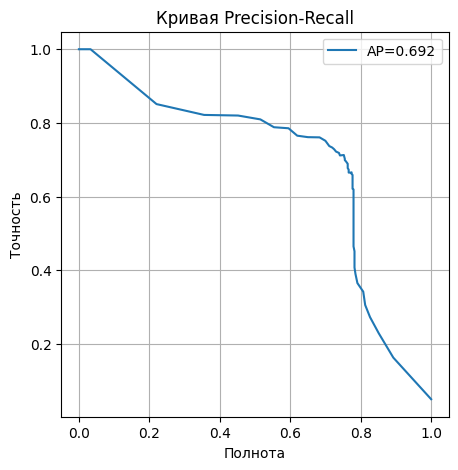

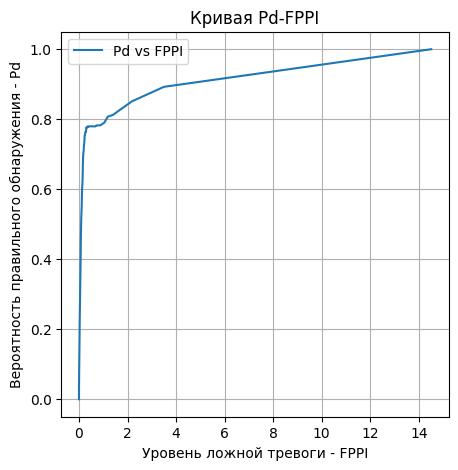

=== Итоговые метрики при пороге confidence = 0.500 ===
Всего изображений N = 476
TP (boxes)   = 282
FP (boxes)   = 163
FN (boxes)   = 81
Всего предсказаний                = 7272
Предсказаний учтено при пороге   = 445
Precision    = 0.6337
Recall (Pd)  = 0.7769
FPPI         = 163 / 476 = 0.342437

=== Метрики при целевом FPPI = 0.1 ===
Найденный порог confidence     = 0.909
Recall (Pd) при этом пороге   = 0.5152


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ----------------- Конфигурация -----------------
LABEL_DIR    = "/content/ThermalUAV2UAV_Dataset/test/labels"
PRED_DIR     = "runs/detect/TESTep30small_new/labels"
IMAGE_DIR = "/content/ThermalUAV2UAV_Dataset/test/images"

CONF_THRESH  = 0.001
IOU_THRESH   = 0.5
TH_METRIC    = 0.5

# ----------------- Функции -----------------
def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w/2) * img_w
    y1 = (yc - h/2) * img_h
    x2 = (xc + w/2) * img_w
    y2 = (yc + h/2) * img_h
    return np.array([x1, y1, x2, y2], dtype=float)

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2-ix1)*(iy2-iy1)
    area1 = (box1[2]-box1[0])*(box1[3]-box1[1])
    area2 = (box2[2]-box2[0])*(box2[3]-box2[1])
    return inter / (area1 + area2 - inter)

# ----------------- Сбор GT и предсказаний -----------------
all_labels  = []
all_scores  = []
per_image_gt   = {}
per_image_pred = {}

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

for img_file in image_files:
    base = os.path.splitext(img_file)[0]
    gt_path = os.path.join(LABEL_DIR, base + ".txt")
    pred_path = os.path.join(PRED_DIR, base + ".txt")

    gt_boxes = []
    if os.path.exists(gt_path) and os.stat(gt_path).st_size > 0:
        gt_boxes = [yolo_to_corners(list(map(float, line.strip().split()[1:5])))
                    for line in open(gt_path) if len(line.strip().split()) >= 5]
    per_image_gt[base] = len(gt_boxes)

    pred_boxes, pred_scores = [], []
    if os.path.exists(pred_path):
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) >= 6:
                score = float(parts[5])
                if score >= CONF_THRESH:
                    pred_scores.append(score)
                    pred_boxes.append(yolo_to_corners(list(map(float, parts[1:5]))))

    used_gt = set()
    per_image_pred[base] = []
    for pbox, pscore in zip(pred_boxes, pred_scores):
        best_iou, best_j = 0.0, -1
        for j, gbox in enumerate(gt_boxes):
            if j in used_gt:
                continue
            cur_iou = iou(pbox, gbox)
            if cur_iou > best_iou:
                best_iou, best_j = cur_iou, j
        is_tp = best_iou >= IOU_THRESH
        if is_tp:
            used_gt.add(best_j)
        all_scores.append(pscore)
        all_labels.append(1 if is_tp else 0)
        per_image_pred[base].append((pscore, is_tp))

    n_fn = len(gt_boxes) - len(used_gt)
    all_scores.extend([0.0] * n_fn)
    all_labels.extend([1] * n_fn)

# ----------------- Построение ROC -----------------
fpr, tpr, _ = roc_curve(all_labels, all_scores)
roc_auc = auc(fpr, tpr)

# ----------------- Ручной PR + AP + Pd-FPPI -----------------
unique_thresholds = np.linspace(0.0, 1.0, 100)
pr_list, re_list = [], []
fp_list, pd_list = [], []

for thresh in unique_thresholds:
    TP = FP = FN = 0
    for fname, ngt in per_image_gt.items():
        preds = per_image_pred.get(fname, [])
        sel = [(s, is_tp) for (s, is_tp) in preds if s >= thresh]
        tp_i = sum(is_tp for _, is_tp in sel)
        fp_i = len(sel) - tp_i
        fn_i = ngt - tp_i
        TP += tp_i
        FP += fp_i
        FN += max(fn_i, 0)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 1.0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    fppi      = FP / N_images

    pr_list.append(precision)
    re_list.append(recall)
    pd_list.append(recall)
    fp_list.append(fppi)

# ----------------- AP (Area under PR curve) -----------------
re_arr = np.array(re_list)
pr_arr = np.array(pr_list)
sorted_idx = np.argsort(re_arr)
re_sorted = re_arr[sorted_idx]
pr_sorted = pr_arr[sorted_idx]
AP = np.trapezoid(pr_sorted, re_sorted)
# ----------------- Визуализация -----------------
plt.figure(figsize=(5,5))
plt.plot(re_list, pr_list, label=f"AP={AP:.3f}")
plt.xlabel("Полнота")
plt.ylabel("Точность")
plt.grid()
plt.legend()
plt.title("Кривая Precision-Recall")
plt.show()


plt.figure(figsize=(5,5))
plt.plot(fp_list, pd_list, label="Pd vs FPPI")
plt.xlabel("Уровень ложной тревоги - FPPI")
plt.ylabel("Вероятность правильного обнаружения - Pd")
plt.grid()
plt.legend()
plt.title("Кривая Pd-FPPI")
plt.show()

# ----------------- Финальный подсчёт при TH_METRIC -----------------
TP = FP = FN = 0
n_total_preds = 0
n_counted_preds = 0
for fname, ngt in per_image_gt.items():
    preds = per_image_pred.get(fname, [])
    n_total_preds += len(preds)
    sel = [(s, is_tp) for (s, is_tp) in preds if s >= TH_METRIC]
    n_counted_preds += len(sel)
    tp_i = sum(is_tp for _, is_tp in sel)
    fp_i = len(sel) - tp_i
    fn_i = ngt - tp_i

    TP += tp_i
    FP += fp_i
    FN += max(fn_i, 0)

Prec = TP / (TP + FP) if TP + FP > 0 else 0
Rec  = TP / (TP + FN) if TP + FN > 0 else 0
FPPI = FP / N_images

print("=== Итоговые метрики при пороге confidence = {:.3f} ===".format(TH_METRIC))
print(f"Всего изображений N = {N_images}")
print(f"TP (boxes)   = {TP}")
print(f"FP (boxes)   = {FP}")
print(f"FN (boxes)   = {FN}")
print(f"Всего предсказаний                = {n_total_preds}")
print(f"Предсказаний учтено при пороге   = {n_counted_preds}")
print(f"Precision    = {Prec:.4f}")
print(f"Recall (Pd)  = {Rec:.4f}")
print(f"FPPI         = {FP} / {N_images} = {FPPI:.6f}")

# ----------------- Поиск метрики при заданном FPPI -----------------
TARGET_FPPI = 0.1

conf_at_fppi = None
pd_at_fppi = None
for fppi_val, pd_val, conf_thresh in zip(fp_list, pd_list, unique_thresholds):
    if fppi_val <= TARGET_FPPI:
        conf_at_fppi = conf_thresh
        pd_at_fppi = pd_val
        break

if conf_at_fppi is not None:
    print(f"\n=== Метрики при целевом FPPI = {TARGET_FPPI} ===")
    print(f"Найденный порог confidence     = {conf_at_fppi:.3f}")
    print(f"Recall (Pd) при этом пороге   = {pd_at_fppi:.4f}")
else:
    print(f"\nFPPI = {TARGET_FPPI} не достигнут ни при одном пороге.")

In [ ]:
%cd /content/yolov5
!rm -rf runs/detect/TESTep30small_bird_new
!python3 detect.py --source '/content/Bird-IR-train/Bird-IR-train/valid/images' --weights '/content/yolov5/runs/train/finetune_with_negatives/weights/best.pt' --save-txt --save-conf --conf 0.001 --iou 0.5 --augment --name 'TESTep30small_bird_new' --exist-ok

/content/yolov5
detect: weights=['/content/yolov5/runs/train/finetune_with_negatives/weights/best.pt'], source=/content/Bird-IR-train/Bird-IR-train/valid/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.001, iou_thres=0.5, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=True, visualize=False, update=False, project=runs/detect, name=TESTep30small_bird_new, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-450-g781b9d57 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7012822 parameters, 0 gradients, 15.8 GFLOPs
image 1/200 /content/Bird-IR-train/Bird-IR-train/valid/images/scene02167_jpg.rf.1f12414941b2feab1cf40427f42dbc51.jpg: 640x640 9 UAVs, 87.8ms
image 2/200 /content/Bird-IR-train/Bird-IR-train/valid/images/scene02168_jpg

In [ ]:
import os
import numpy as np

# ----------------- Конфигурация -----------------
pred_dir       = "runs/detect/TESTep30small_bird_new/labels"
image_dir      = "/content/Bird-IR-train/Bird-IR-train/valid/images"
gt_dir         = "/content/Bird-IR-train/Bird-IR-train/valid/labels"
conf_threshold = 0.5
iou_threshold  = 0.5
# ------------------------------------------------

def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return np.array([x1, y1, x2, y2])

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2 - ix1) * (iy2 - iy1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area1 + area2 - inter)

# Список изображений
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

# Карты предсказаний и GT
pred_map = {
    os.path.splitext(f)[0]: os.path.join(pred_dir, f)
    for f in os.listdir(pred_dir)
    if f.endswith(".txt")
}
gt_map = {
    os.path.splitext(f)[0]: os.path.join(gt_dir, f)
    for f in os.listdir(gt_dir)
    if f.endswith(".txt")
}

images_without_preds = 0
images_completely_empty = 0
total_fp = 0
fp_on_birds = 0
total_gt_birds = 0

for img in image_files:
    base = os.path.splitext(img)[0]
    pred_path = pred_map.get(base, None)
    gt_path   = gt_map.get(base, None)

    # Загружаем GT боксы птиц
    gt_boxes = []
    if gt_path and os.stat(gt_path).st_size > 0:
        for line in open(gt_path):
            parts = line.strip().split()
            if len(parts) >= 5:
                gt_box = yolo_to_corners(list(map(float, parts[1:5])))
                gt_boxes.append(gt_box)
    total_gt_birds += len(gt_boxes)

    # Считаем предсказания
    preds = []
    if pred_path and os.stat(pred_path).st_size > 0:
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) < 6:
                continue
            conf = float(parts[5])
            if conf >= conf_threshold:
                box = yolo_to_corners(list(map(float, parts[1:5])))
                preds.append(box)

    if len(preds) == 0:
        images_without_preds += 1
        if pred_path is None or os.stat(pred_path).st_size == 0:
            images_completely_empty += 1
        continue

    total_fp += len(preds)

    # Проверяем пересечения предсказаний с GT боксами
    for pbox in preds:
        matched = False
        for gbox in gt_boxes:
            if iou(pbox, gbox) >= iou_threshold:
                matched = True
                break
        if matched:
            fp_on_birds += 1

# Метрики
fppi_total = total_fp / N_images
fppi_birds = fp_on_birds / N_images

# Вывод
print(f"Всего изображений:                         {N_images}")
print(f"Число птиц на этих изображениях:           {total_gt_birds}")
print(f"Порог confidence:                          {conf_threshold:.2f}")
print(f"Общее число предсказаний (FP):             {total_fp}")
print(f"FPPI (все срабатывания):                   {fppi_total:.6f}")
print(f"FP на птицах (восприняты как дрон):        {fp_on_birds}")
print(f"FPPI на птицах:                            {fppi_birds:.6f}")
print(f"Изображений без предсказаний:              {images_without_preds}")
print(f"Из них полностью пустых файлов (нет .txt): {images_completely_empty}")


Всего изображений:                         200
Число птиц на этих изображениях:           229
Порог confidence:                          0.50
Общее число предсказаний (FP):             10
FPPI (все срабатывания):                   0.050000
FP на птицах (восприняты как дрон):        10
FPPI на птицах:                            0.050000
Изображений без предсказаний:              190
Из них полностью пустых файлов (нет .txt): 12


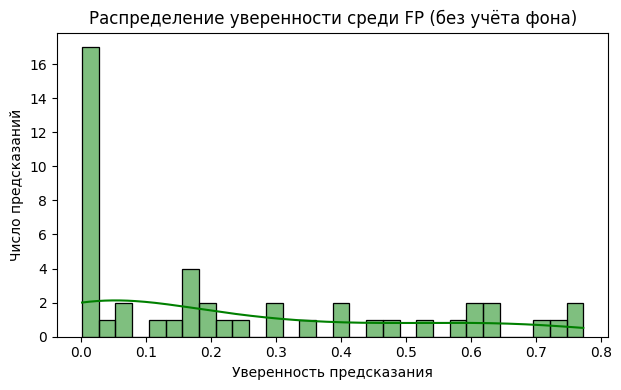

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------- Конфигурация -----------------
pred_dir       = "runs/detect/TESTep30small_bird_new/labels"
image_dir      = "/content/Bird-IR-train/Bird-IR-train/valid/images"
gt_dir         = "/content/Bird-IR-train/Bird-IR-train/valid/labels"
conf_threshold = 0.5
iou_threshold  = 0.5
class_id_drone = 0
# ------------------------------------------------

def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return np.array([x1, y1, x2, y2])

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2 - ix1) * (iy2 - iy1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area1 + area2 - inter)

# Список изображений
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

# Карты предсказаний и GT
pred_map = {
    os.path.splitext(f)[0]: os.path.join(pred_dir, f)
    for f in os.listdir(pred_dir)
    if f.endswith(".txt")
}
gt_map = {
    os.path.splitext(f)[0]: os.path.join(gt_dir, f)
    for f in os.listdir(gt_dir)
    if f.endswith(".txt")
}

images_without_preds = 0
images_completely_empty = 0
total_fp = 0
fp_on_birds = 0
total_gt_birds = 0

all_fp_confidences = []
bird_fp_confidences = []

for img in image_files:
    base = os.path.splitext(img)[0]
    pred_path = pred_map.get(base, None)
    gt_path   = gt_map.get(base, None)

    # Загружаем GT боксы птиц
    gt_boxes = []
    if gt_path and os.stat(gt_path).st_size > 0:
        for line in open(gt_path):
            parts = line.strip().split()
            if len(parts) >= 5:
                gt_box = yolo_to_corners(list(map(float, parts[1:5])))
                gt_boxes.append(gt_box)
    total_gt_birds += len(gt_boxes)

    # Считаем предсказания
    preds = []
    pred_confs = []
    if pred_path and os.stat(pred_path).st_size > 0:
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) < 6:
                continue
            cid = int(parts[0])
            conf = float(parts[5])
            if cid == class_id_drone:
                box = yolo_to_corners(list(map(float, parts[1:5])))
                preds.append(box)
                pred_confs.append(conf)

    if len(preds) == 0:
        images_without_preds += 1
        if pred_path is None or os.stat(pred_path).st_size == 0:
            images_completely_empty += 1
        continue

    total_fp += len(preds)
    all_fp_confidences.extend(pred_confs)

    # Проверяем пересечения предсказаний с GT боксами
    for pbox, conf in zip(preds, pred_confs):
        matched = False
        for gbox in gt_boxes:
            if iou(pbox, gbox) >= iou_threshold:
                matched = True
                break
        if matched:
            fp_on_birds += 1
            bird_fp_confidences.append(conf)

# Метрики
fppi_total = total_fp / N_images
fppi_birds = fp_on_birds / N_images

# Построение гистограмм
plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 2)
sns.histplot(bird_fp_confidences, bins=30, kde=True, color='green')
plt.xlabel("Уверенность предсказания")
plt.ylabel("Число предсказаний")
plt.title("Распределение уверенности среди FP (без учёта фона)")

plt.tight_layout()
plt.show()


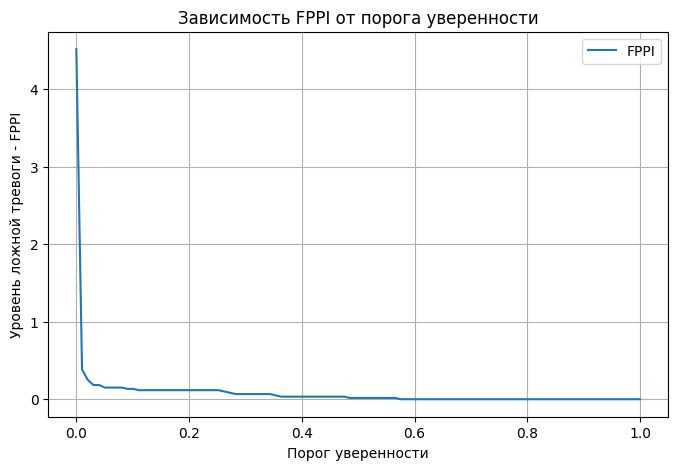


=== Confidence при FPPI <= 0.01 ===
Confidence threshold = 0.5758
FPPI = 0.000000


In [ ]:
conf_thresholds = np.linspace(0.0, 1.0, 100)
fppi_values = []

for conf_thresh in conf_thresholds:
    total_fp = 0

    for img in image_files:
        base = os.path.splitext(img)[0]
        pred_path = pred_map.get(base, None)

        # Предсказания
        preds = []
        if pred_path and os.stat(pred_path).st_size > 0:
            for line in open(pred_path):
                parts = line.strip().split()
                if len(parts) < 6:
                    continue
                cid = int(parts[0])
                conf = float(parts[5])
                if cid == class_id_drone and conf >= conf_thresh:
                    preds.append(1)  # просто считаем, сколько срабатываний

        total_fp += len(preds)

    fppi = total_fp / N_images
    fppi_values.append(fppi)

plt.figure(figsize=(8, 5))
plt.plot(conf_thresholds, fppi_values, label="FPPI")
plt.xlabel("Порог уверенности")
plt.ylabel("Уровень ложной тревоги - FPPI")
plt.title("Зависимость FPPI от порога уверенности")
plt.grid(True)
plt.legend()
plt.show()

# ----------------- Поиск confidence при заданном FPPI -----------------
TARGET_FPPI = 0.01

conf_at_target = None
for conf, fppi in zip(conf_thresholds, fppi_values):
    if fppi <= TARGET_FPPI:
        conf_at_target = conf
        break

if conf_at_target is not None:
    print(f"\n=== Confidence при FPPI <= {TARGET_FPPI} ===")
    print(f"Confidence threshold = {conf_at_target:.4f}")
    print(f"FPPI = {fppi:.6f}")
else:
    print(f"\nFPPI = {TARGET_FPPI} не достигнут ни при одном пороге.")




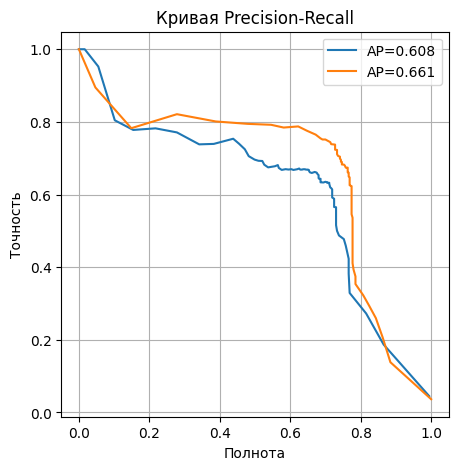

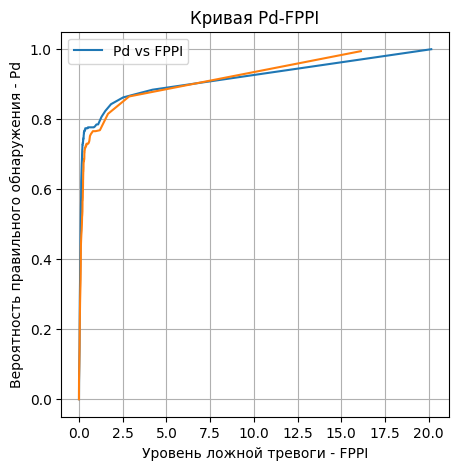

=== Итоговые метрики при пороге confidence = 0.500 ===
Всего изображений N = 476
TP (boxes)   = 278
FP (boxes)   = 149
FN (boxes)   = 85
Всего предсказаний                = 9953
Предсказаний учтено при пороге   = 427
Precision    = 0.6511
Recall (Pd)  = 0.7658
FPPI         = 149 / 476 = 0.313025

=== Метрики при целевом FPPI = 0.1 ===
Найденный порог confidence     = 0.909
Recall (Pd) при этом пороге   = 0.4793


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ----------------- Конфигурация -----------------
LABEL_DIR    = "/content/ThermalUAV2UAV_Dataset/test/labels"
PRED_DIR     = "runs/detect/TESTep30small_new/labels"
IMAGE_DIR = "/content/ThermalUAV2UAV_Dataset/test/images"

CONF_THRESH  = 0.001
IOU_THRESH   = 0.5
TH_METRIC    = 0.5

# ----------------- Функции -----------------
def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w/2) * img_w
    y1 = (yc - h/2) * img_h
    x2 = (xc + w/2) * img_w
    y2 = (yc + h/2) * img_h
    return np.array([x1, y1, x2, y2], dtype=float)

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2-ix1)*(iy2-iy1)
    area1 = (box1[2]-box1[0])*(box1[3]-box1[1])
    area2 = (box2[2]-box2[0])*(box2[3]-box2[1])
    return inter / (area1 + area2 - inter)

# ----------------- Сбор GT и предсказаний -----------------
all_labels  = []
all_scores  = []
per_image_gt   = {}
per_image_pred = {}

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
N_images = len(image_files)

for img_file in image_files:
    base = os.path.splitext(img_file)[0]
    gt_path = os.path.join(LABEL_DIR, base + ".txt")
    pred_path = os.path.join(PRED_DIR, base + ".txt")

    gt_boxes = []
    if os.path.exists(gt_path) and os.stat(gt_path).st_size > 0:
        gt_boxes = [yolo_to_corners(list(map(float, line.strip().split()[1:5])))
                    for line in open(gt_path) if len(line.strip().split()) >= 5]
    per_image_gt[base] = len(gt_boxes)

    pred_boxes, pred_scores = [], []
    if os.path.exists(pred_path):
        for line in open(pred_path):
            parts = line.strip().split()
            if len(parts) >= 6:
                score = float(parts[5])
                if score >= CONF_THRESH:
                    pred_scores.append(score)
                    pred_boxes.append(yolo_to_corners(list(map(float, parts[1:5]))))

    used_gt = set()
    per_image_pred[base] = []
    for pbox, pscore in zip(pred_boxes, pred_scores):
        best_iou, best_j = 0.0, -1
        for j, gbox in enumerate(gt_boxes):
            if j in used_gt:
                continue
            cur_iou = iou(pbox, gbox)
            if cur_iou > best_iou:
                best_iou, best_j = cur_iou, j
        is_tp = best_iou >= IOU_THRESH
        if is_tp:
            used_gt.add(best_j)
        all_scores.append(pscore)
        all_labels.append(1 if is_tp else 0)
        per_image_pred[base].append((pscore, is_tp))

    n_fn = len(gt_boxes) - len(used_gt)
    all_scores.extend([0.0] * n_fn)
    all_labels.extend([1] * n_fn)

# ----------------- Построение ROC -----------------
fpr, tpr, _ = roc_curve(all_labels, all_scores)
roc_auc = auc(fpr, tpr)

# ----------------- Ручной PR + AP + Pd-FPPI -----------------
unique_thresholds = np.linspace(0.0, 1.0, 100)
pr_list, re_list = [], []
fp_list, pd_list = [], []

for thresh in unique_thresholds:
    TP = FP = FN = 0
    for fname, ngt in per_image_gt.items():
        preds = per_image_pred.get(fname, [])
        sel = [(s, is_tp) for (s, is_tp) in preds if s >= thresh]
        tp_i = sum(is_tp for _, is_tp in sel)
        fp_i = len(sel) - tp_i
        fn_i = ngt - tp_i
        TP += tp_i
        FP += fp_i
        FN += max(fn_i, 0)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 1.0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    fppi      = FP / N_images

    pr_list.append(precision)
    re_list.append(recall)
    pd_list.append(recall)
    fp_list.append(fppi)

# ----------------- AP (Area under PR curve) -----------------
re_arr = np.array(re_list)
pr_arr = np.array(pr_list)
sorted_idx = np.argsort(re_arr)
re_sorted = re_arr[sorted_idx]
pr_sorted = pr_arr[sorted_idx]
AP = np.trapezoid(pr_sorted, re_sorted)
# ----------------- Визуализация -----------------
plt.figure(figsize=(5,5))
plt.plot(re_list_1, pr_list_1, label=f"AP={AP_1:.3f}")
plt.plot(re_list, pr_list, label=f"AP={AP:.3f}")
plt.xlabel("Полнота")
plt.ylabel("Точность")
plt.grid()
plt.legend()
plt.title("Кривая Precision-Recall")
plt.show()


plt.figure(figsize=(5,5))
plt.plot(fp_list, pd_list, label="Pd vs FPPI")
plt.plot(fp_list_1, pd_list_1)
plt.xlabel("Уровень ложной тревоги - FPPI")
plt.ylabel("Вероятность правильного обнаружения - Pd")
plt.grid()
plt.legend()
plt.title("Кривая Pd-FPPI")
plt.show()

# ----------------- Финальный подсчёт при TH_METRIC -----------------
TP = FP = FN = 0
n_total_preds = 0
n_counted_preds = 0
for fname, ngt in per_image_gt.items():
    preds = per_image_pred.get(fname, [])
    n_total_preds += len(preds)
    sel = [(s, is_tp) for (s, is_tp) in preds if s >= TH_METRIC]
    n_counted_preds += len(sel)
    tp_i = sum(is_tp for _, is_tp in sel)
    fp_i = len(sel) - tp_i
    fn_i = ngt - tp_i

    TP += tp_i
    FP += fp_i
    FN += max(fn_i, 0)

Prec = TP / (TP + FP) if TP + FP > 0 else 0
Rec  = TP / (TP + FN) if TP + FN > 0 else 0
FPPI = FP / N_images

print("=== Итоговые метрики при пороге confidence = {:.3f} ===".format(TH_METRIC))
print(f"Всего изображений N = {N_images}")
print(f"TP (boxes)   = {TP}")
print(f"FP (boxes)   = {FP}")
print(f"FN (boxes)   = {FN}")
print(f"Всего предсказаний                = {n_total_preds}")
print(f"Предсказаний учтено при пороге   = {n_counted_preds}")
print(f"Precision    = {Prec:.4f}")
print(f"Recall (Pd)  = {Rec:.4f}")
print(f"FPPI         = {FP} / {N_images} = {FPPI:.6f}")

# ----------------- Поиск метрики при заданном FPPI -----------------
TARGET_FPPI = 0.1

conf_at_fppi = None
pd_at_fppi = None
for fppi_val, pd_val, conf_thresh in zip(fp_list, pd_list, unique_thresholds):
    if fppi_val <= TARGET_FPPI:
        conf_at_fppi = conf_thresh
        pd_at_fppi = pd_val
        break

if conf_at_fppi is not None:
    print(f"\n=== Метрики при целевом FPPI = {TARGET_FPPI} ===")
    print(f"Найденный порог confidence     = {conf_at_fppi:.3f}")
    print(f"Recall (Pd) при этом пороге   = {pd_at_fppi:.4f}")
else:
    print(f"\nFPPI = {TARGET_FPPI} не достигнут ни при одном пороге.")

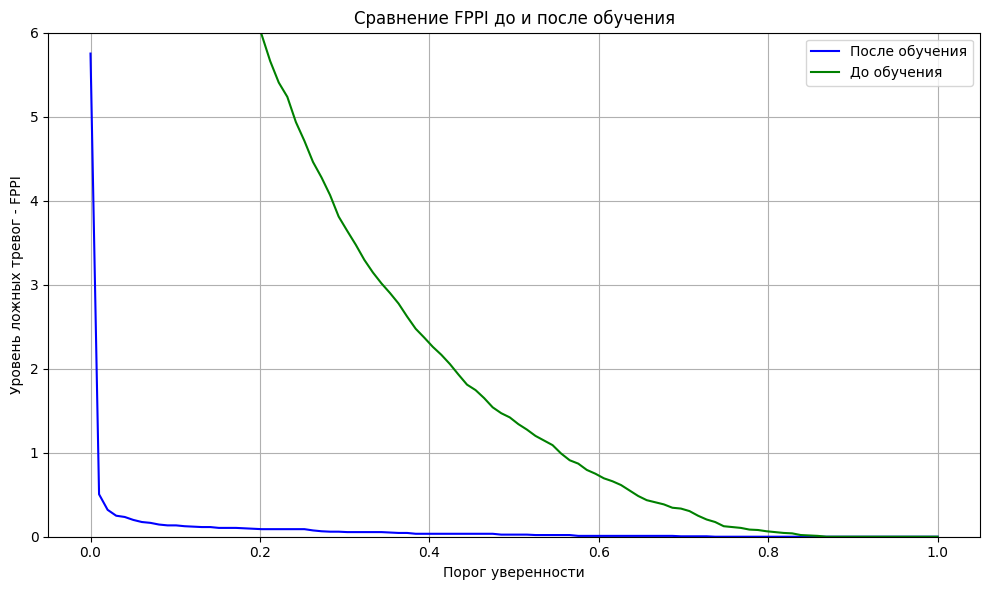

In [ ]:
# Две конфигурации (можешь переименовать их, чтобы отражали суть)
pred_dir_1 = "runs/detect/TESTep30small_bird_new/labels"
pred_dir_2 = "runs/detect/TESTep30small_bird/labels"

image_dir = "/content/Bird-IR-train/Bird-IR-train/valid/images"
class_id_drone = 0

def compute_fppi_vs_conf(pred_dir, image_dir, class_id=0, N_bins=100):
    conf_thresholds = np.linspace(0.0, 1.0, N_bins)
    fppi_values = []

    image_files = sorted([
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    N_images = len(image_files)

    pred_map = {
        os.path.splitext(f)[0]: os.path.join(pred_dir, f)
        for f in os.listdir(pred_dir)
        if f.endswith(".txt")
    }

    for conf_thresh in conf_thresholds:
        total_fp = 0

        for img in image_files:
            base = os.path.splitext(img)[0]
            pred_path = pred_map.get(base, None)

            if pred_path and os.stat(pred_path).st_size > 0:
                for line in open(pred_path):
                    parts = line.strip().split()
                    if len(parts) < 6:
                        continue
                    cid = int(parts[0])
                    conf = float(parts[5])
                    if cid == class_id and conf >= conf_thresh:
                        total_fp += 1

        fppi = total_fp / N_images
        fppi_values.append(fppi)

    return conf_thresholds, fppi_values

# Получаем кривые
conf1, fppi1 = compute_fppi_vs_conf(pred_dir_1, image_dir, class_id_drone)
conf2, fppi2 = compute_fppi_vs_conf(pred_dir_2, image_dir, class_id_drone)

# Построение
plt.figure(figsize=(10, 6))
plt.ylim(0, 6)  # Ограничение оси ординат от 0 до 10
plt.plot(conf1, fppi1, label="После обучения", color='blue')
plt.plot(conf2, fppi2, label="До обучения", color='green')
plt.xlabel("Порог уверенности")
plt.ylabel("Уровень ложных тревог - FPPI")
plt.title("Сравнение FPPI до и после обучения")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline

# ---------------- Утилитарные функции ----------------

def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w/2) * img_w
    y1 = (yc - h/2) * img_h
    x2 = (xc + w/2) * img_w
    y2 = (yc + h/2) * img_h
    return np.array([x1, y1, x2, y2], dtype=float)

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2 - ix1) * (iy2 - iy1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area1 + area2 - inter)

def load_gt(gt_dir, img_dir):
    files = sorted(f for f in os.listdir(img_dir)
                   if f.lower().endswith((".jpg", ".png", ".jpeg")))
    per_image = {}
    for fn in files:
        base = os.path.splitext(fn)[0]
        path = os.path.join(gt_dir, base + ".txt")
        gts = []
        if os.path.exists(path):
            for line in open(path):
                parts = line.strip().split()
                if len(parts) >= 5:
                    xywh = list(map(float, parts[1:5]))
                    gts.append(yolo_to_corners(xywh))
        per_image[base] = gts
    return per_image, len(files)

def load_predictions(pred_dir, img_dir, conf_min=0.0):
    files = sorted(f for f in os.listdir(img_dir)
                   if f.lower().endswith((".jpg", ".png", ".jpeg")))
    per_image = {}
    for fn in files:
        base = os.path.splitext(fn)[0]
        path = os.path.join(pred_dir, base + ".txt")
        preds = []
        if os.path.exists(path):
            for line in open(path):
                parts = line.strip().split()
                if len(parts) >= 6:
                    score = float(parts[5])
                    if score >= conf_min:
                        xywh = list(map(float, parts[1:5]))
                        box = yolo_to_corners(xywh)
                        preds.append((score, box))
        per_image[base] = preds
    return per_image, len(files)

def match_image(preds, gts, iou_thr):
    used = set()
    tp = 0
    for score, pbox in preds:
        best_i, best_j = 0.0, -1
        for j, gbox in enumerate(gts):
            if j in used: continue
            cur = iou(pbox, gbox)
            if cur > best_i:
                best_i, best_j = cur, j
        if best_i >= iou_thr:
            tp += 1
            used.add(best_j)
    fp = len(preds) - tp
    fn = len(gts)   - tp
    return tp, fp, fn

def compute_det_curve(gt_dir, pred_dir, img_dir,
                      iou_thr=0.5, thresholds=np.linspace(0,1,500)):
    per_gt, N = load_gt(gt_dir, img_dir)
    per_pr, _ = load_predictions(pred_dir, img_dir, conf_min=0.0)
    pd_list, fppi_list = [], []
    for thr in thresholds:
        TP = FP = FN = 0
        for img_id, gts in per_gt.items():
            preds = per_pr[img_id]
            sel = [(s,b) for s,b in preds if s >= thr]
            tp, fp, fn = match_image(sel, gts, iou_thr)
            TP += tp; FP += fp; FN += fn
        Pd   = TP/(TP+FN) if TP+FN>0 else 0.0
        FPPI = FP/N
        pd_list.append(Pd)
        fppi_list.append(FPPI)
    return thresholds, fppi_list, pd_list

def smooth_curve(x, y, points=500):
    idx = np.argsort(x)
    x_s, y_s = np.array(x)[idx], np.array(y)[idx]
    spl = make_interp_spline(x_s, y_s)
    x_new = np.linspace(x_s.min(), x_s.max(), points)
    y_new = spl(x_new)
    return x_new, y_new

def find_threshold_for_fppi(thresholds, fppi_list, pd_list, target_fppi):
    fppi = np.array(fppi_list)
    pd   = np.array(pd_list)
    idxs = np.where(fppi <= target_fppi)[0]
    if len(idxs) == 0:
        return None, None
    pd_sub = pd[idxs]
    max_pd = pd_sub.max()
    idxs_max_pd = idxs[np.where(pd_sub == max_pd)[0]]
    best_idx = idxs_max_pd[np.argmax([thresholds[i] for i in idxs_max_pd])]
    return thresholds[best_idx], pd[best_idx]


# ---------------------- Main ----------------------

if __name__ == "__main__":
    # настройки
    IOU_THR      = 0.5
    TARGET_FPPI  = 0.001
    THRESHOLDS   = np.linspace(0.0, 1.0, 500)

    # пути к данным
    GT_DIR      = "/content/ThermalUAV2UAV_Dataset/test/labels"
    IMG_DRONES  = "/content/ThermalUAV2UAV_Dataset/test/images"
    PRED1_DR    = "runs/detect/TESTep30small/labels"
    PRED2_DR    = "runs/detect/TESTep30small_new/labels"

    IMG_BIRDS   = "/content/Bird-IR-train/valid/images"
    PRED1_BR    = "runs/detect/TESTep30small_bird/labels"
    PRED2_BR    = "runs/detect/TESTep30small_bird_new/labels"

    # DET для дронов обеих конфигураций
    th1, fppi1_dr, pd1 = compute_det_curve(
        GT_DIR, PRED1_DR, IMG_DRONES,
        iou_thr=IOU_THR, thresholds=THRESHOLDS
    )
    th2, fppi2_dr, pd2 = compute_det_curve(
        GT_DIR, PRED2_DR, IMG_DRONES,
        iou_thr=IOU_THR, thresholds=THRESHOLDS
    )
    # DET для птиц (чтобы FPPI было по птицам)
    _, fppi1_br, _ = compute_det_curve(
        GT_DIR, PRED1_BR, IMG_BIRDS,
        iou_thr=IOU_THR, thresholds=THRESHOLDS
    )
    _, fppi2_br, _ = compute_det_curve(
        GT_DIR, PRED2_BR, IMG_BIRDS,
        iou_thr=IOU_THR, thresholds=THRESHOLDS
    )

    # сглаживаем
    x11, y11 = smooth_curve(fppi1_br, pd1)
    x22, y22 = smooth_curve(fppi2_br, pd2)

    # --- 1) Общий график обеих кривых ---
    plt.figure(figsize=(6,5))
    plt.plot(x11, y11, '-', lw=2, label="Config #1")
    plt.plot(x22, y22, '-', lw=2, label="Config #2")
    plt.xlabel("FPPI (birds)"); plt.ylabel("Pd (drones)")
    plt.title("DET-curve (smoothed) — обе конфигурации")
    plt.grid(True); plt.legend()
    plt.show()

    # --- 2) Отдельная кривая Config #1 ---
    plt.figure(figsize=(6,5))
    plt.plot(x11, y11, 'C0-', lw=2)
    plt.xlabel("FPPI (birds)"); plt.ylabel("Pd (drones)")
    plt.title("DET-curve (Config #1)")
    plt.grid(True)
    plt.show()

    # --- 3) Отдельная кривая Config #2 ---
    plt.figure(figsize=(6,5))
    plt.plot(x22, y22, 'C1-', lw=2)
    plt.xlabel("FPPI (birds)"); plt.ylabel("Pd (drones)")
    plt.title("DET-curve (Config #2)")
    plt.grid(True)
    plt.show()

    # --- 4) Поиск порогов для заданного TARGET_FPPI ---
    thr_1, pd_1 = find_threshold_for_fppi(th1, fppi1_br, pd1, TARGET_FPPI)
    thr_2, pd_2 = find_threshold_for_fppi(th2, fppi2_br, pd2, TARGET_FPPI)

    print(f"\n=== Результаты для TARGET_FPPI = {TARGET_FPPI:.4f} ===")
    if thr_1 is None:
        print("Config #1: FPPI > target при любых порогах")
    else:
        print(f"Config #1: threshold = {thr_1:.4f}, Pd = {pd_1:.4f}")
    if thr_2 is None:
        print("Config #2: FPPI > target при любых порогах")
    else:
        print(f"Config #2: threshold = {thr_2:.4f}, Pd = {pd_2:.4f}")

ValueError: Expect x to not have duplicates

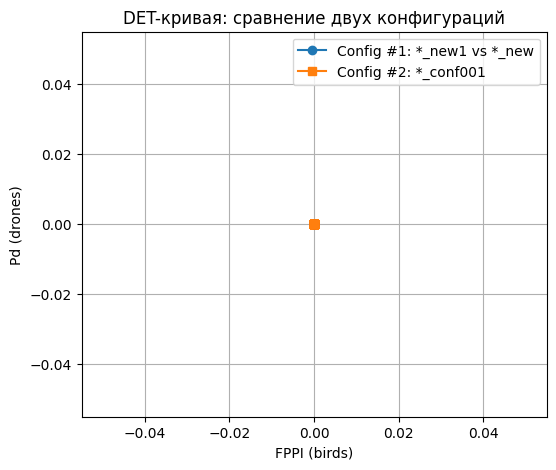

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# --- Вспомогательные функции (копируем из вашего кода) ---
def yolo_to_corners(xywh, img_w=640, img_h=512):
    xc, yc, w, h = xywh
    x1 = (xc - w/2) * img_w
    y1 = (yc - h/2) * img_h
    x2 = (xc + w/2) * img_w
    y2 = (yc + h/2) * img_h
    return np.array([x1, y1, x2, y2], dtype=float)

def iou(box1, box2):
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    if ix2 <= ix1 or iy2 <= iy1:
        return 0.0
    inter = (ix2-ix1)*(iy2-iy1)
    area1 = (box1[2]-box1[0])*(box1[3]-box1[1])
    area2 = (box2[2]-box2[0])*(box2[3]-box2[1])
    return inter / (area1 + area2 - inter)

def load_predictions(pred_dir, img_dir, conf_min=0.0):
    img_files = sorted([f for f in os.listdir(img_dir)
                        if f.lower().endswith((".jpg",".png"))])
    per_image = {}
    for fn in img_files:
        base = os.path.splitext(fn)[0]
        path = os.path.join(pred_dir, base+".txt")
        preds = []
        if os.path.exists(path):
            for line in open(path):
                parts = line.strip().split()
                if len(parts)>=6:
                    s = float(parts[5])
                    if s>=conf_min:
                        box = yolo_to_corners(list(map(float, parts[1:5])))
                        preds.append((s,box))
        per_image[base] = preds
    return per_image, len(img_files)

def load_gt(gt_dir, img_dir):
    img_files = sorted([f for f in os.listdir(img_dir)
                        if f.lower().endswith((".jpg",".png"))])
    per_image = {}
    for fn in img_files:
        base = os.path.splitext(fn)[0]
        path = os.path.join(gt_dir, base+".txt")
        gts = []
        if os.path.exists(path):
            for line in open(path):
                parts = line.strip().split()
                if len(parts)>=5:
                    box = yolo_to_corners(list(map(float, parts[1:5])))
                    gts.append(box)
        per_image[base] = gts
    return per_image, len(img_files)

def match_image(preds, gt_boxes, iou_thr):
    used = set()
    TP = FP = 0
    for s, pbox in preds:
        best_i, best_j = 0, -1
        for j, gbox in enumerate(gt_boxes):
            if j in used: continue
            cur = iou(pbox, gbox)
            if cur>best_i:
                best_i, best_j = cur, j
        if best_i>=iou_thr:
            TP += 1
            used.add(best_j)
        else:
            FP += 1
    FN = len(gt_boxes) - len(used)
    return TP, FP, FN

# --- Функция, которая для заданных директорий возвращает DET-кривую ---
def compute_det_curve(
        drone_gt_dir, drone_pred_dir, drone_img_dir,
        bird_pred_dir,  bird_img_dir,
        iou_thr=0.5,
        thresholds=np.linspace(0,1,100)
    ):
    drone_gt, _       = load_gt   (drone_gt_dir, drone_img_dir)
    drone_pred, _     = load_predictions(drone_pred_dir, drone_img_dir)
    bird_pred, N_bird = load_predictions(bird_pred_dir,  bird_img_dir)

    pd_list   = []
    fppi_list = []

    for thr in thresholds:
        # Pd на датасете с дронами
        TP_d=FP_d=FN_d=0
        for img_id, gt_boxes in drone_gt.items():
            sel = [(s,box) for s,box in drone_pred[img_id] if s>=thr]
            tp, fp, fn = match_image(sel, gt_boxes, iou_thr)
            TP_d+=tp; FP_d+=fp; FN_d+=fn
        Pd = TP_d/(TP_d+FN_d) if TP_d+FN_d>0 else 0

        # FPPI на датасете с птицами
        FP_b = 0
        for img_id, preds_b in bird_pred.items():
            FP_b += sum(1 for s,_ in preds_b if s>=thr)
        FPPI = FP_b / N_bird

        pd_list.append(Pd)
        fppi_list.append(FPPI)

    return fppi_list, pd_list

# --- Задаём пороги once для всех кривых ---
THRESHOLDS = np.linspace(0.0, 1.0, 100)

# --- Конфигурация 1 ---
fppi1, pd1 = compute_det_curve(
    drone_gt_dir   = "/content/ThermalUAV2UAV_Dataset/test/labels",
    drone_pred_dir = "runs/detect/ep30small_conf001_new/labels",
    drone_img_dir  = "/content/ThermalUAV2UAV_Dataset/test/images",
    bird_pred_dir  = "runs/detect/ep30small_bird_conf001_new1/labels",
    bird_img_dir   = "/content/Bird-IR-train/valid/images",
    iou_thr        = 0.5,
    thresholds     = THRESHOLDS
)

# --- Конфигурация 2 ---
fppi2, pd2 = compute_det_curve(
    drone_gt_dir   = "/content/ThermalUAV2UAV_Dataset/test/labels",
    drone_pred_dir = "runs/detect/ep30small_conf001/labels",
    drone_img_dir  = "/content/ThermalUAV2UAV_Dataset/test/images",
    bird_pred_dir  = "runs/detect/ep30small_bird_conf001/labels",
    bird_img_dir   = "/content/Bird-IR-train/valid/images",
    iou_thr        = 0.5,
    thresholds     = THRESHOLDS
)

# --- Рисуем обе кривые на одном графике ---
plt.figure(figsize=(6,5))
plt.plot(fppi1, pd1, '-o', label="Config #1: *_new1 vs *_new")
plt.plot(fppi2, pd2, '-s', label="Config #2: *_conf001")
plt.xlabel("FPPI (birds)")
plt.ylabel("Pd (drones)")
plt.title("DET-кривая: сравнение двух конфигураций")
plt.grid(True)
plt.legend()
plt.show()


#Дообучение

##30 EPOCHS - SMALL YOLO

In [ ]:
model = YOLO('yolov8s.pt')
results = model.train(data='/content/ThermalUAV2UAV_Dataset/dataset.yaml', epochs=30, imgsz=640, batch=16, save=True, rect=True)

Ultralytics YOLOv8.0.196 🚀 Python-3.10.12 torch-2.0.1+cu118 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/ThermalUAV2UAV_Dataset/dataset.yaml, epochs=30, patience=50, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=None, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=True, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, show=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, vid_stride=1, stream_buffer=False, line_width=None, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, boxes=True, format=torchscript, k

In [ ]:
model = YOLO('/content/runs/detect/train2/weights/best.pt')
metrics = model.val(data='/content/ThermalUAV2UAV_Dataset/dataset.yaml', imgsz=640, batch=16, rect=True, split='val')

Ultralytics YOLOv8.0.196 🚀 Python-3.10.12 torch-2.0.1+cu118 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 168 layers, 11125971 parameters, 0 gradients, 28.4 GFLOPs
val: Scanning /content/ThermalUAV2UAV_Dataset/val/labels.cache... 646 images, 220 backgrounds, 0 corrupt: 100%|██████████| 866/866 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 55/55 [00:13<00:00,  4.15it/s]
                   all        866        723      0.908      0.939      0.964      0.747
Speed: 0.9ms preprocess, 7.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs/detect/val3


##METRICS ON TEST SET

In [ ]:
model = YOLO('/content/runs/detect/train2/weights/best.pt')
metrics = model.val(data='/content/ThermalUAV2UAV_Dataset/dataset.yaml', imgsz=640, batch=16, rect=True, split='test')

Ultralytics YOLOv8.0.196 🚀 Python-3.10.12 torch-2.0.1+cu118 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 168 layers, 11125971 parameters, 0 gradients, 28.4 GFLOPs
val: Scanning /content/ThermalUAV2UAV_Dataset/test/labels.cache... 324 images, 152 backgrounds, 0 corrupt: 100%|██████████| 476/476 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 30/30 [00:08<00:00,  3.46it/s]
                   all        476        363      0.889      0.934      0.955      0.726
Speed: 1.3ms preprocess, 7.7ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to runs/detect/val4


##ZIP RESULTS TO SAVE THEM

In [ ]:
!zip -r /content/runs_results_yolo8.zip /content/runs/detect

  adding: content/runs/detect/ (stored 0%)
  adding: content/runs/detect/train2/ (stored 0%)
  adding: content/runs/detect/train2/val_batch1_labels.jpg (deflated 11%)
  adding: content/runs/detect/train2/val_batch1_pred.jpg (deflated 11%)
  adding: content/runs/detect/train2/confusion_matrix_normalized.png (deflated 38%)
  adding: content/runs/detect/train2/args.yaml (deflated 50%)
  adding: content/runs/detect/train2/weights/ (stored 0%)
  adding: content/runs/detect/train2/weights/last.pt (deflated 8%)
  adding: content/runs/detect/train2/weights/best.pt (deflated 8%)
  adding: content/runs/detect/train2/train_batch0.jpg (deflated 12%)
  adding: content/runs/detect/train2/val_batch2_pred.jpg (deflated 9%)
  adding: content/runs/detect/train2/F1_curve.png (deflated 17%)
  adding: content/runs/detect/train2/PR_curve.png (deflated 25%)
  adding: content/runs/detect/train2/train_batch3161.jpg (deflated 17%)
  adding: content/runs/detect/train2/results.csv (deflated 84%)
  adding: content